# Klasifikasi Citra Dokumen Pindaian (RVL-CDIP, 16 kelas)

Notebook ini adalah **alur analisis** tugas. Semua fungsi dan kelas ada di paket `src/` (lengkap dengan docstring),
notebook hanya memanggilnya dan menafsirkan hasilnya. Metrik lomba adalah **Categorical Accuracy**.

| tahap | isi | modul |
|---|---|---|
| 0 | persiapan lingkungan dan konfigurasi | `src/config.py` |
| 1 | pemahaman data & problem statement | `src/data.py` |
| 2 | data cleaning (integritas file, duplikat, label konflik, fold berbasis grup) | `src/data.py` |
| 3 | exploratory data analysis | `src/visualize.py` |
| 4 | preprocessing & augmentasi, noise floor | `src/dataset.py`, `src/ensemble.py` |
| 6 | konstruksi model dan training | `src/models.py`, `src/train.py` |
| 7 | model selection (ensemble) | `src/ensemble.py` |
| 8 | evaluasi model | `src/visualize.py` |
| 9 | visualisasi hasil | `src/visualize.py` |
| 10 | optimalisasi (TTA, bobot ensemble, OCR opsional) dan submission | `src/ensemble.py`, `src/ocr.py` |

(Penomoran mengikuti daftar tahapan tugas, jadi nomor 5 memang tidak ada.)

**Aturan yang dipegang:** PyTorch; backbone dari Hugging Face Hub; checkpoint yang sudah di-finetune pada dataset serupa
(RVL-CDIP) dipakai karena diizinkan panitia; tidak ada pseudo-label; duplikat train dan test hanya dilaporkan, labelnya
tidak disalin; tidak ada flip horizontal saat augmentasi.

**Cara pakai di Kaggle:** tambahkan data lomba sebagai input, accelerator **GPU T4 x2**, Internet **ON**, lalu *Run All*
(sekitar 1,3 sampai 1,5 jam). Sel pertama memakai folder `src/` repo ini kalau ada; kalau tidak (misalnya di Kaggle), salinan `src/` yang tertanam di sel itu dipakai, jadi tidak perlu clone.
Uji asap di CPU: `DOC_SMOKE=1 DOC_PRETRAINED=0`.

## 0. Persiapan lingkungan dan konfigurasi

In [1]:
import os, sys, io, base64, zipfile, subprocess
from pathlib import Path

# Paket src/ dicari berurutan: (1) repo ini (lokal atau di-clone), (2) Kaggle Dataset berisi repo,
# (3) clone dari REPO_URL kalau diisi, (4) salinan src/ yang tertanam di sel ini (isinya sama persis dengan folder src/ di repo),
# sehingga notebook bisa langsung Run All di Kaggle tanpa menyiapkan repo.
REPO_URL = os.environ.get("DOC_REPO_URL", "")      # opsional, misalnya https://github.com/<user>/<repo>.git
SRC_TERTANAM = "..."

def cari_repo():
    '''Kembalikan folder yang berisi src/config.py, memakai salinan tertanam kalau repo tidak tersedia.'''
    kandidat = [Path.cwd(), Path.cwd().parent]
    if Path("/kaggle/input").exists():
        kandidat += list(Path("/kaggle/input").glob("*")) + list(Path("/kaggle/input").glob("*/*"))
    for c in kandidat:
        if (c / "src" / "config.py").exists():
            return c
    tujuan = Path("/kaggle/working/repo") if Path("/kaggle/working").exists() else Path.cwd() / "repo"
    if REPO_URL:
        r = subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(tujuan)])
        if r.returncode == 0 and (tujuan / "src" / "config.py").exists():
            return tujuan
    zipfile.ZipFile(io.BytesIO(base64.b64decode(SRC_TERTANAM))).extractall(tujuan)
    return tujuan

REPO = cari_repo()
sys.path.insert(0, str(REPO))
print("src dimuat dari:", REPO)

from src.config import Konfigurasi, daftar_anggota, seed_everything, pastikan_paket
for m, p in [("timm", "timm"), ("imagehash", "imagehash"), ("seaborn", "seaborn")]:
    pastikan_paket(m, p)

src dimuat dari: /kaggle/working/repo


In [2]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import timm
from collections import Counter
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report

from src import data as D, dataset as DS, ensemble as E, train as TR, visualize as V
from src.data import Konteks
from src.models import buat_model

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 90

cfg = Konfigurasi.dari_env()          # semua sakelar bisa diubah lewat variabel lingkungan DOC_*
cfg.siapkan_folder()
seed_everything(cfg.seed)
ANGGOTA = daftar_anggota(cfg)
LAPORAN = cfg.reports_dir             # gambar dan ringkasan kecil untuk README
print("torch", torch.__version__, "| timm", timm.__version__, "| GPU:", torch.cuda.device_count(), "| device:", cfg.device)
print("profil:", cfg.profil, "| smoke:", cfg.smoke, "| folder kerja:", cfg.dasar)
pd.DataFrame(ANGGOTA).drop(columns="aktif")

torch 2.11.0+cu128 | timm 1.0.29 | GPU: 2 | device: cuda
profil: rvlcdip_ft | smoke: False | folder kerja: /kaggle/working


,name,backend,hub,head_rvl,view,size,epochs,bs,ckpt,lr,layer_decay
0,dit_large_rvlft,hf,microsoft/dit-large-finetuned-rvlcdip,True,full,"(224, 224)",2,32,True,0.00001,0.9
1,donut_rvlcdip,donut,naver-clova-ix/donut-base-finetuned-rvlcdip,NaN,full,"(2560, 1920)",0,8,NaN,0.00000,NaN
2,dit_base_rvlft,hf,microsoft/dit-base-finetuned-rvlcdip,True,full,"(224, 224)",2,64,NaN,0.00002,0.8


## 1. Pemahaman data & problem statement

**Problem statement.** Diberikan satu halaman dokumen hasil pindai (TIFF grayscale), tentukan kategorinya dari 16 kelas
(0 sampai 15). Model dinilai dengan akurasi: proporsi gambar test yang kelasnya ditebak benar.

Beberapa hal yang membuat kasus ini berbeda dari klasifikasi citra alami:

* Informasi pembeda sering ada di **teks kecil** dan **tata letak** (tabel, kolom, kotak isian), bukan di warna atau tekstur.
  Resize ke 224 x 224 menghilangkan banyak detail, jadi resolusi 384 sampai 448 dipakai.
* Bagian **atas halaman** (kop surat, tulisan MEMORANDUM, header To:/From:/Subject:) sangat informatif untuk memo, email, dan letter,
  sehingga ada anggota ensemble khusus yang hanya melihat header.
* Label RVL-CDIP dikenal **berderau** dan ada gambar kembar. Plafon akurasi lebih rendah dari 100%, dan duplikat bisa bocor antar fold.
* Pasangan kelas yang secara alami tertukar: form vs questionnaire, scientific_report vs scientific_publication vs specification,
  letter vs memo vs email, budget vs invoice.

In [3]:
D.pulihkan_artefak_kaggle(cfg)        # lanjut dari output sesi Kaggle sebelumnya kalau ada
train_df, test_df, sub_contoh, CLASSES = D.muat_csv(cfg)
NUM_CLASSES = len(CLASSES)
display(train_df.head(3)); display(test_df.head(3))
pd.Series(CLASSES, name="class_name").to_frame()

cek path train:   0%|          | 0/32003 [00:00<?, ?it/s]

cek path test:   0%|          | 0/7994 [00:00<?, ?it/s]

folder data: /kaggle/input/datasets/affrizawildanfauzan/mewtwo/document-image-classification-sd234504 | train 32003 | test 7994


,id,filename,class_name,label,path
0,train_00001,train/resume/50497291-7292.tif,resume,12,/kaggle/input/datasets/affrizawildanfauzan/mew...
1,train_00002,train/scientific_publication/50728670-8670.tif,scientific_publication,13,/kaggle/input/datasets/affrizawildanfauzan/mew...
2,train_00003,train/scientific_report/87112192.tif,scientific_report,14,/kaggle/input/datasets/affrizawildanfauzan/mew...


,id,filename,path
0,test_00001,test/test_00001.tif,/kaggle/input/datasets/affrizawildanfauzan/mew...
1,test_00002,test/test_00002.tif,/kaggle/input/datasets/affrizawildanfauzan/mew...
2,test_00003,test/test_00003.tif,/kaggle/input/datasets/affrizawildanfauzan/mew...


,class_name
0,advertisement
1,budget
2,email
3,file_folder
4,form
5,handwritten
6,invoice
7,letter
8,memo
9,news_article


## 2. Data cleaning

Langkah pembersihan (mengikuti pedoman *dataset-doctor* dan *leak-hunt*):

1. **Integritas file**: setiap TIFF dibuka, dicatat mode piksel, ukuran, jumlah halaman (multi-page), kompresi, DPI, dan ukuran file.
   File yang gagal dibaca dibuang dari data latih.
2. **Duplikat persis** (MD5 isi file) dan **near-duplicate** (perceptual hash, jarak Hamming kecil) di dalam train.
   Gambar kembar dikelompokkan dengan union-find. Kelompok ini dipakai sebagai *group* saat membagi fold,
   supaya gambar kembar tidak sekaligus muncul di train dan validasi (sumber CV yang terlalu optimis).
3. Kelompok kembar dengan **label berbeda** adalah kandidat label salah. Dengan `DROP_KONFLIK=True` gambarnya dibuang dari data latih.
   Ini membersihkan data latih, bukan mengganti label.
4. **Duplikat train vs test** hanya dihitung dan dilaporkan. Labelnya tidak dipakai untuk prediksi.

Satu kali pemindaian (paralel) menghasilkan semua informasi di atas sekaligus, lalu disimpan ke `artefak/` supaya sesi berikutnya tidak perlu mengulang (`src/data.py: scan_semua`).

In [4]:
scan_tr = D.scan_semua(cfg, list(train_df["path"]), "train")
scan_te = D.scan_semua(cfg, list(test_df["path"]), "test")
train_df = train_df.merge(scan_tr, on="path", how="left")
test_df = test_df.merge(scan_te, on="path", how="left")
print("gagal dibaca train:", int((~train_df["ok"]).sum()), "| test:", int((~test_df["ok"]).sum()))
display(train_df.loc[~train_df["ok"]].reindex(columns=["id", "filename", "err"]).head())
print("Mode piksel:", Counter(train_df["mode"]).most_common())
print("Jumlah halaman per TIFF:", Counter(train_df["n_frames"]).most_common())
print("Kompresi:", Counter(train_df["compression"]).most_common(5))
print("Tinggi gambar:", Counter(train_df["h"]).most_common(5))

scan train:   0%|          | 0/32003 [00:00<?, ?it/s]

scan test:   0%|          | 0/7994 [00:00<?, ?it/s]

gagal dibaca train: 1 | test: 0


,id,filename,err
8794,train_08795,train/scientific_publication/2500126531_250012...,"UnidentifiedImageError(""cannot identify image ..."


Mode piksel: [('L', 32002), (nan, 1)]
Jumlah halaman per TIFF: [(1.0, 32002), (nan, 1)]
Kompresi: [('packbits', 32002), (nan, 1)]
Tinggi gambar: [(1000.0, 32002), (nan, 1)]


In [5]:
train_df, n_pairs = D.kelompokkan_duplikat(train_df, cfg.phash_max_hamming)
print(f"pasangan near-duplicate (Hamming <= {cfg.phash_max_hamming}):", n_pairs)
print("gambar yang punya kembar di train:", int(train_df["dup"].sum()),
      "| kelompok kembar:", train_df.loc[train_df["dup"], "grp"].nunique())
print("gambar di kelompok kembar dengan label berbeda (kandidat label salah):", int(train_df["konflik"].sum()))
display(train_df[train_df["konflik"]].sort_values("grp")[["id", "class_name", "grp"]].head(12))

dup_test = D.laporan_duplikat_test(train_df, test_df)   # HANYA dilaporkan, label tidak disalin
print("duplikat train vs test:", dup_test)

pasangan near-duplicate (Hamming <= 4): 9275
gambar yang punya kembar di train: 2509 | kelompok kembar: 491
gambar di kelompok kembar dengan label berbeda (kandidat label salah): 1098


,id,class_name,grp
3373,train_03374,file_folder,3373
995,train_00996,file_folder,3373
618,train_00619,scientific_publication,3373
1622,train_01623,budget,5805
5805,train_05806,scientific_report,5805
31949,train_31950,questionnaire,6718
31226,train_31227,memo,6718
31809,train_31810,specification,6718
1859,train_01860,memo,6718
1950,train_01951,invoice,6718


duplikat train vs test: {'md5_identik': 25, 'phash_identik': 119, 'n_test': 7994}


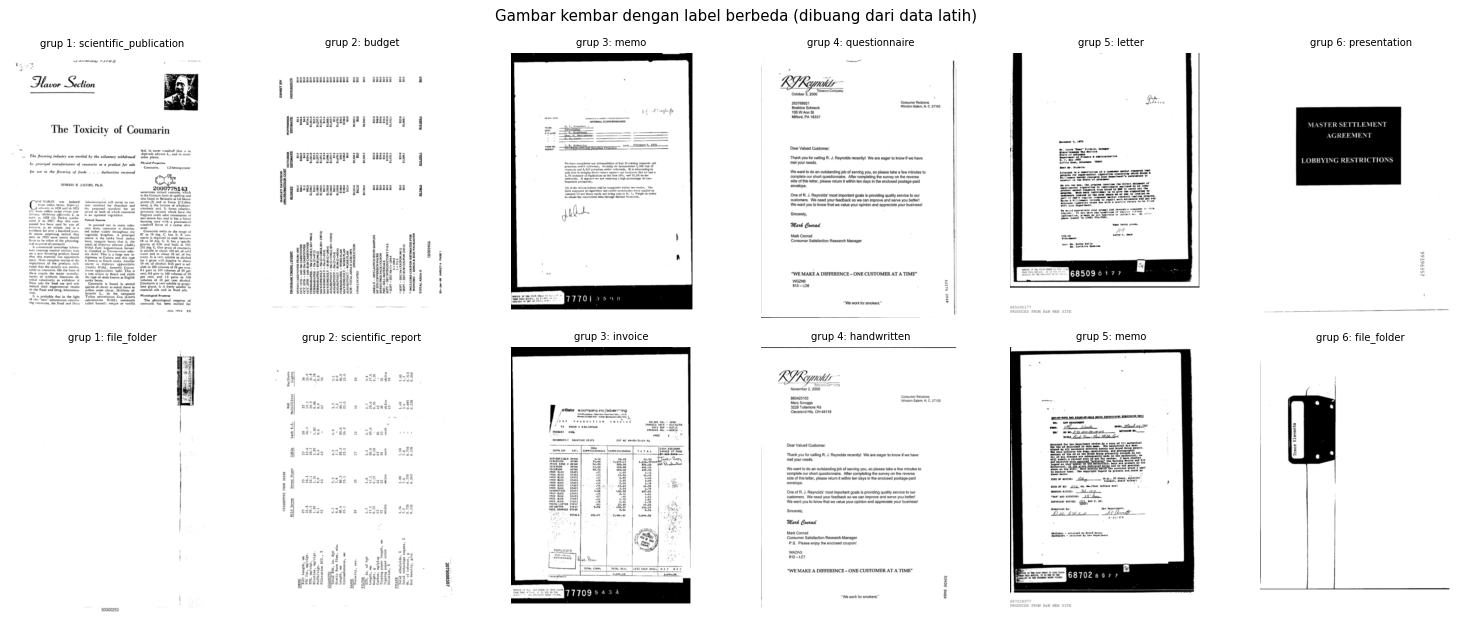

70

In [6]:
V.plot_pasangan_konflik(train_df, CLASSES, simpan=LAPORAN / "duplikat_konflik.png")

Gambar kembar dengan label berbeda adalah bukti langsung **derau label** RVL-CDIP (Larson dkk., 2023 memperkirakan sekitar 8%).
Model tidak mungkin benar untuk kedua label sekaligus, jadi gambar ini dibuang dari data latih agar model tidak belajar
dari sinyal yang saling bertentangan. Gambar test tidak disentuh.

In [7]:
# Cek kebocoran lewat metadata: kalau metadata saja bisa menebak kelas jauh di atas 1/16, ada sinyal non-visual
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score, GroupKFold
ok = train_df["ok"]
meta_cols = ["w", "h", "file_kb", "n_frames", "mean", "ink"]
cv_meta = cross_val_score(HistGradientBoostingClassifier(max_iter=20 if cfg.smoke else 100),
                          train_df.loc[ok, meta_cols].astype(float).values, train_df.loc[ok, "label"].values,
                          groups=train_df.loc[ok, "grp"].values, cv=GroupKFold(3), scoring="accuracy")
print("akurasi model metadata saja:", cv_meta.round(3), "| peluang acak:", round(1 / NUM_CLASSES, 3))

akurasi model metadata saja: [0.329 0.296 0.295] | peluang acak: 0.062


Interpretasi singkat:

* Metadata seperti ukuran file dan proporsi tinta wajar sedikit informatif (iklan lebih gelap, file_folder hampir kosong).
  Informasi ini memang bagian dari gambar, jadi model citra akan menangkapnya sendiri. Bukan kebocoran label.
* Nama file train memakai ID dokumen asli, sedangkan test sudah dianonimkan, sehingga nama file tidak bisa dipakai untuk test.
* Gambar test **tidak** dicocokkan dengan RVL-CDIP publik. Mengambil label dari dataset publik adalah pelanggaran.

In [8]:
n_awal = len(train_df)
train_df, tr_idx, va_idx = D.bersihkan_dan_bagi(cfg, train_df)
assert test_df["ok"].all(), "ada gambar test rusak, cek manual"
ctx = Konteks(cfg, train_df, test_df, CLASSES, tr_idx, va_idx)
y_va = ctx.y_va
print(f"data latih: {n_awal} -> {len(train_df)} gambar setelah cleaning | train {len(tr_idx)} | holdout {len(va_idx)}")

data latih: 32003 -> 30904 gambar setelah cleaning | train 24816 | holdout 6088


## 3. Exploratory Data Analysis (EDA)

Semua grafik juga disimpan ke `reports/` dan dikutip di README.

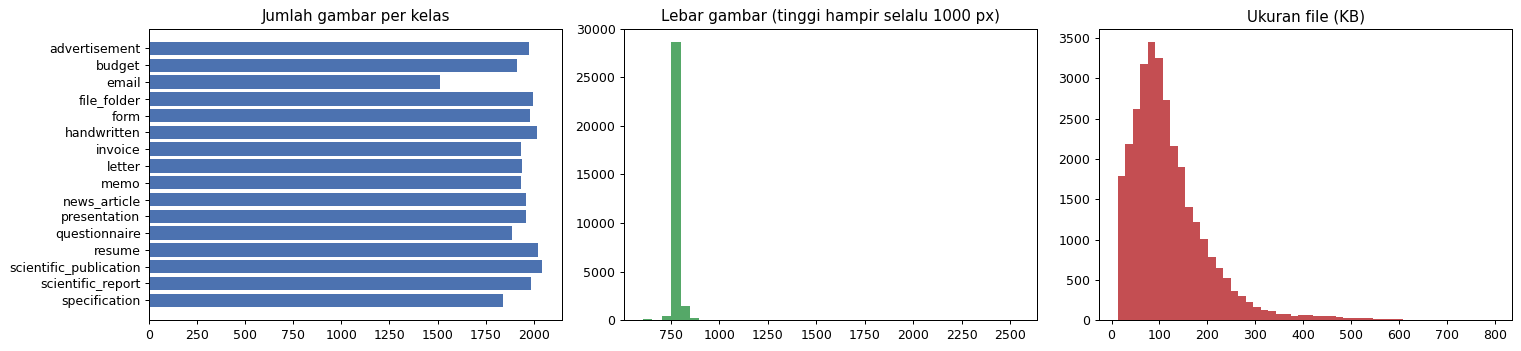

rasio kelas terbesar / terkecil: 1.352 -> praktis seimbang, tidak perlu bobot kelas


In [9]:
vc = V.plot_distribusi(train_df, CLASSES, simpan=LAPORAN / "eda_distribusi.png")
print("rasio kelas terbesar / terkecil:", round(vc.max() / vc.min(), 3), "-> praktis seimbang, tidak perlu bobot kelas")

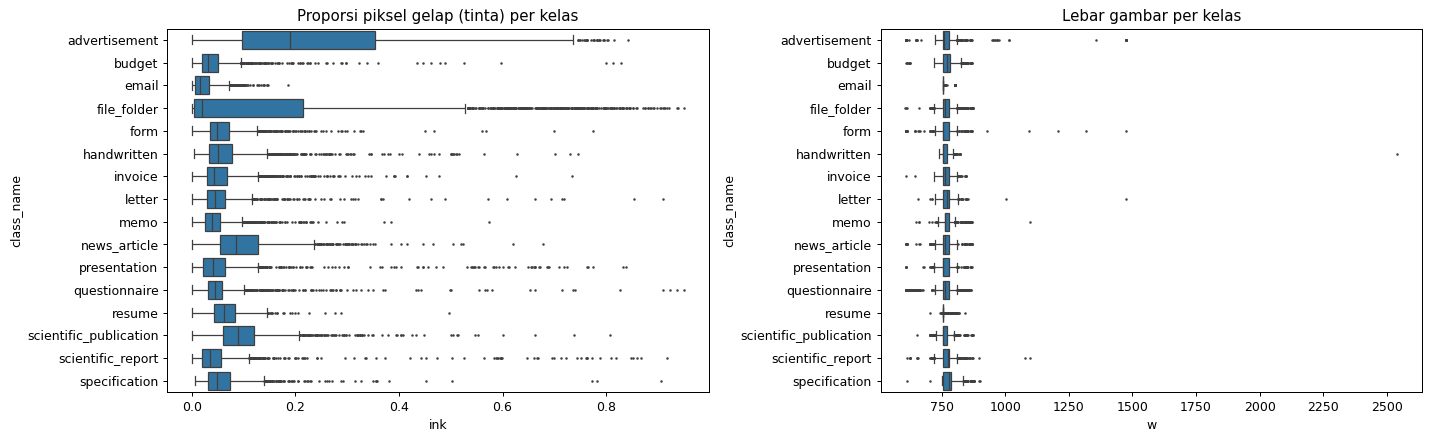

In [10]:
V.plot_box_per_kelas(train_df, CLASSES, simpan=LAPORAN / "eda_box_per_kelas.png")

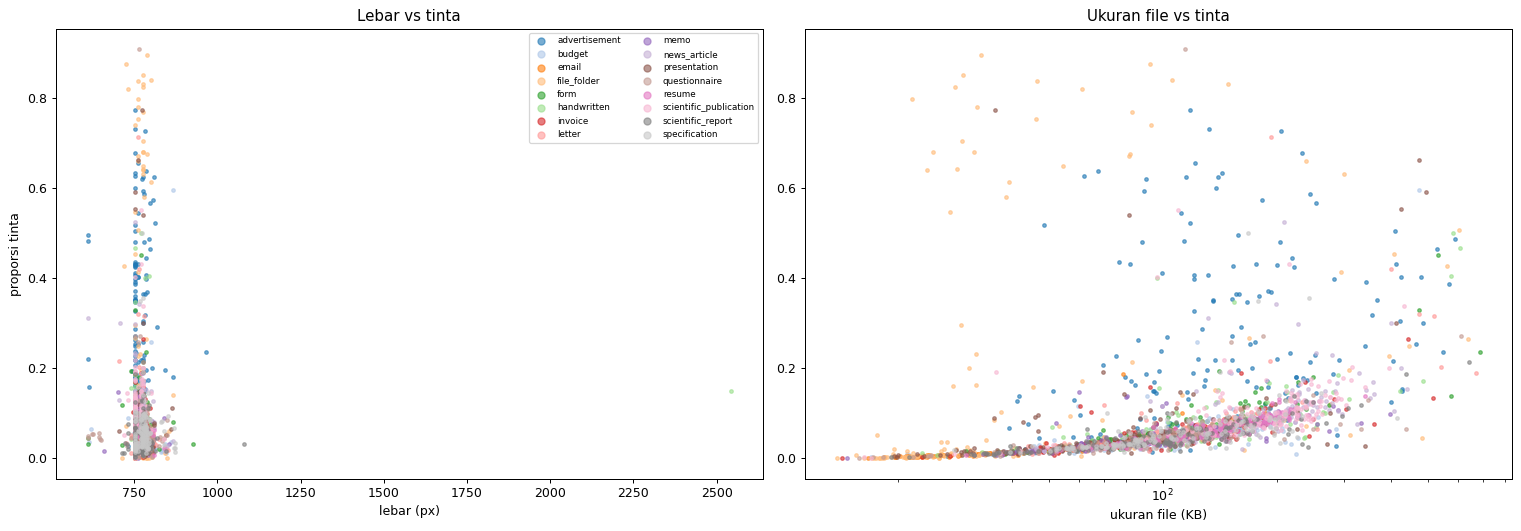

In [11]:
V.plot_scatter_meta(train_df, CLASSES, seed=cfg.seed, simpan=LAPORAN / "eda_scatter_meta.png")

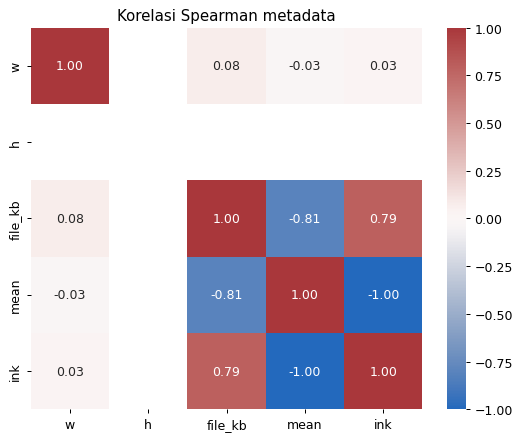

,w,h,file_kb,mean,ink
w,1.00,NaN,0.08,-0.03,0.03
h,NaN,NaN,NaN,NaN,NaN
file_kb,0.08,NaN,1.00,-0.81,0.79
mean,-0.03,NaN,-0.81,1.00,-1.00
ink,0.03,NaN,0.79,-1.00,1.00


In [12]:
V.plot_korelasi_meta(train_df, simpan=LAPORAN / "eda_korelasi_meta.png").round(2)

**Cara membaca.** Sebaran lebar vs tinta memperlihatkan kelas yang mudah dipisah dari statistik sederhana
(advertisement dan file_folder jauh lebih gelap karena berisi foto atau sampul map hasil pindai),
sedangkan sebagian besar kelas lain bertumpuk. Artinya model harus membaca isi halaman (teks dan tata letak),
bukan sekadar statistik global. Korelasi metadata memastikan fitur-fitur ini saling berkaitan (ukuran file naik bersama tinta),
jadi tidak ada satu fitur metadata yang membawa informasi label tersembunyi.

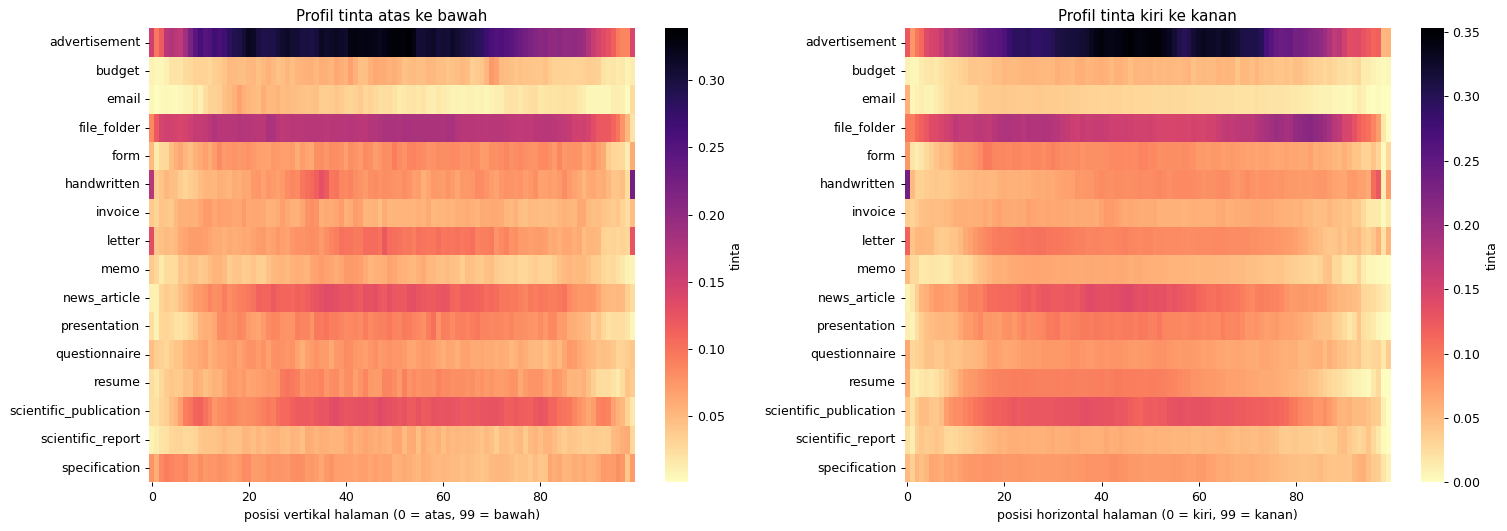

In [13]:
V.plot_profil_tinta(train_df, CLASSES, seed=cfg.seed, simpan=LAPORAN / "eda_profil_tinta.png")

**Profil tinta** adalah rata-rata proporsi piksel gelap per baris (kiri) dan per kolom (kanan) halaman, untuk setiap kelas.
Grafik ini adalah "sidik jari" tata letak. Advertisement dan file_folder paling gelap hampir di seluruh halaman;
news_article dan scientific_publication padat di tengah halaman (teks berkolom); email, memo, letter, dan scientific_report
terang dengan tinta tipis yang tersebar. Kelas dengan profil khas mudah dikenali model citra yang melihat seluruh halaman (DiT),
sedangkan kelas dengan profil hampir sama (letter vs memo, form vs questionnaire, budget vs invoice) hanya bisa dibedakan
dari isi teksnya, alasan Donut ditambahkan.

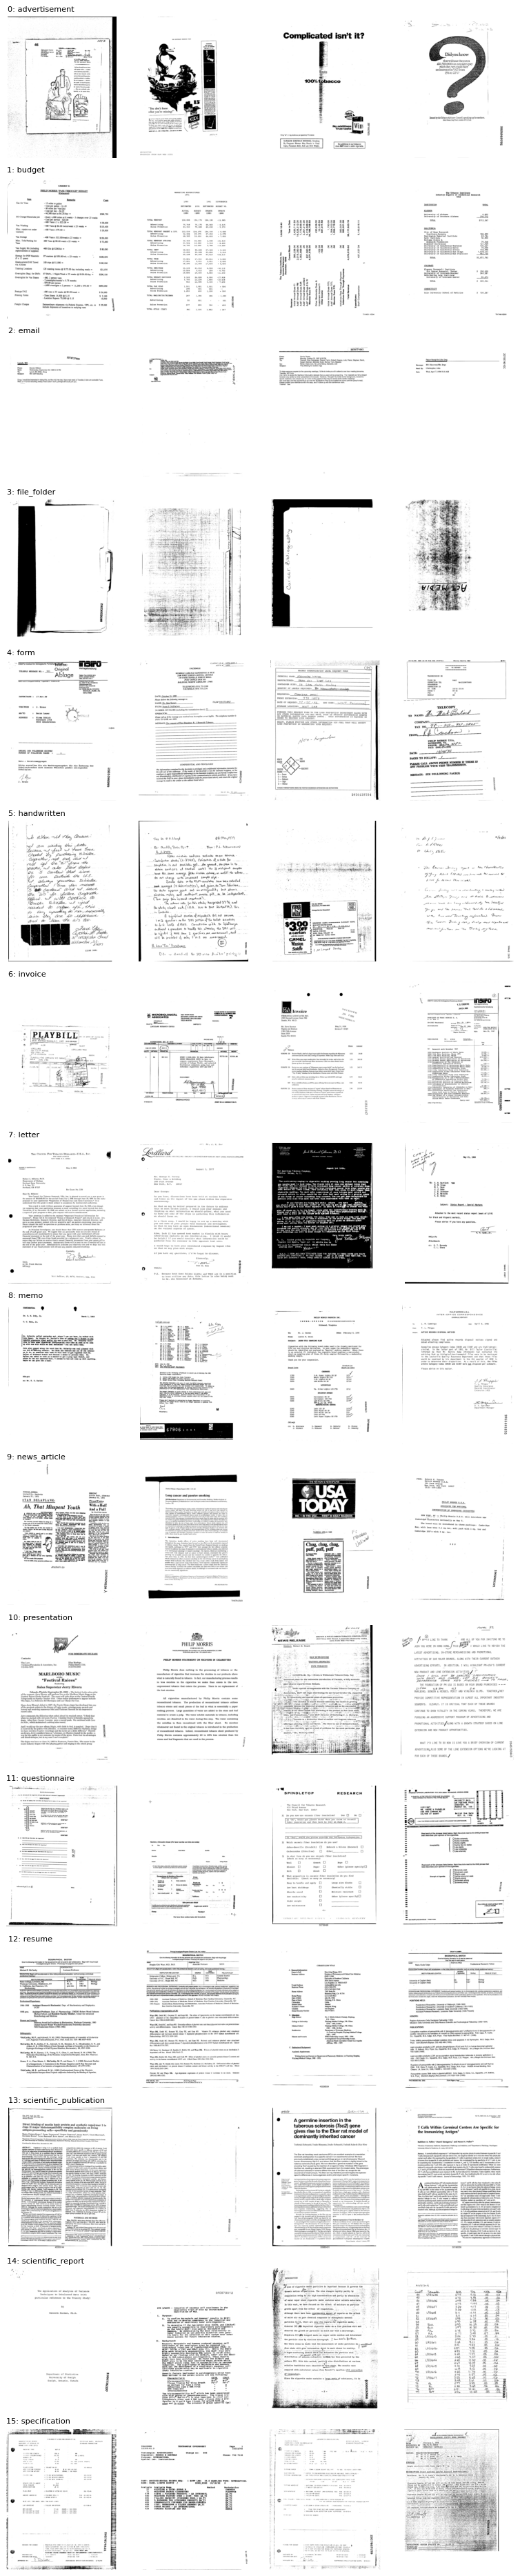

In [14]:
V.plot_contoh_per_kelas(train_df, CLASSES, seed=cfg.seed, simpan=LAPORAN / "eda_contoh_per_kelas.png")

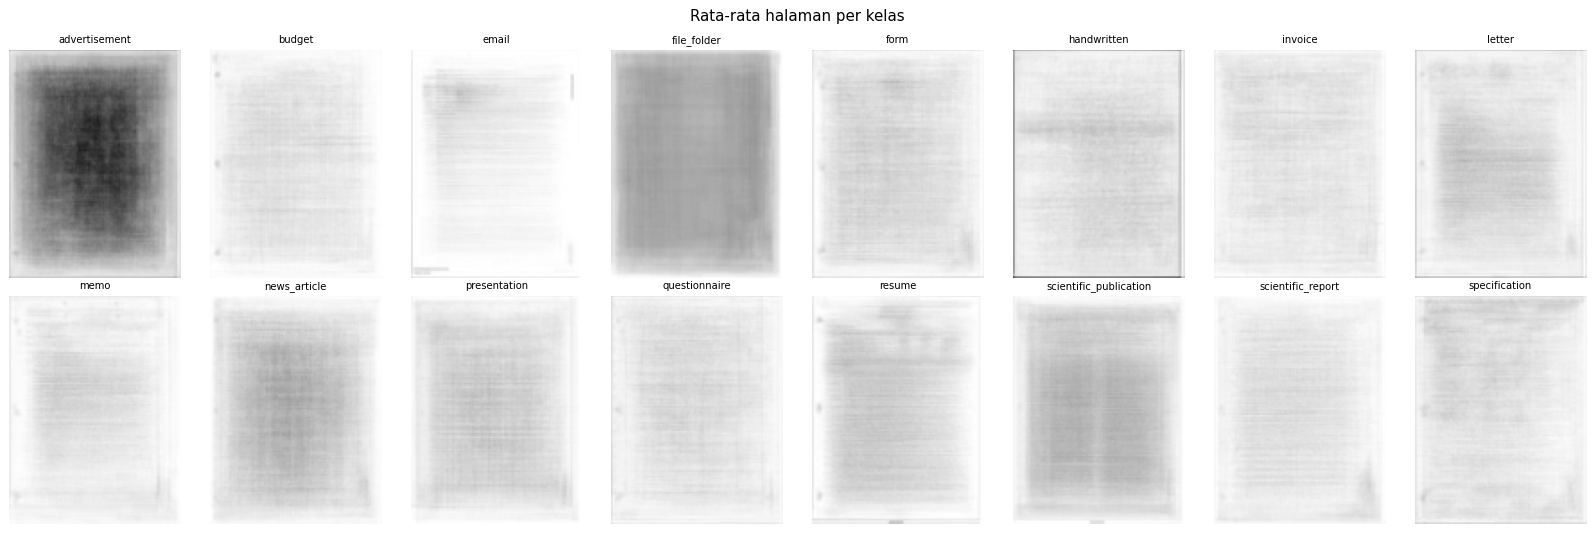

In [15]:
V.plot_rata2_halaman(train_df, CLASSES, seed=cfg.seed, simpan=LAPORAN / "eda_rata2_halaman.png")

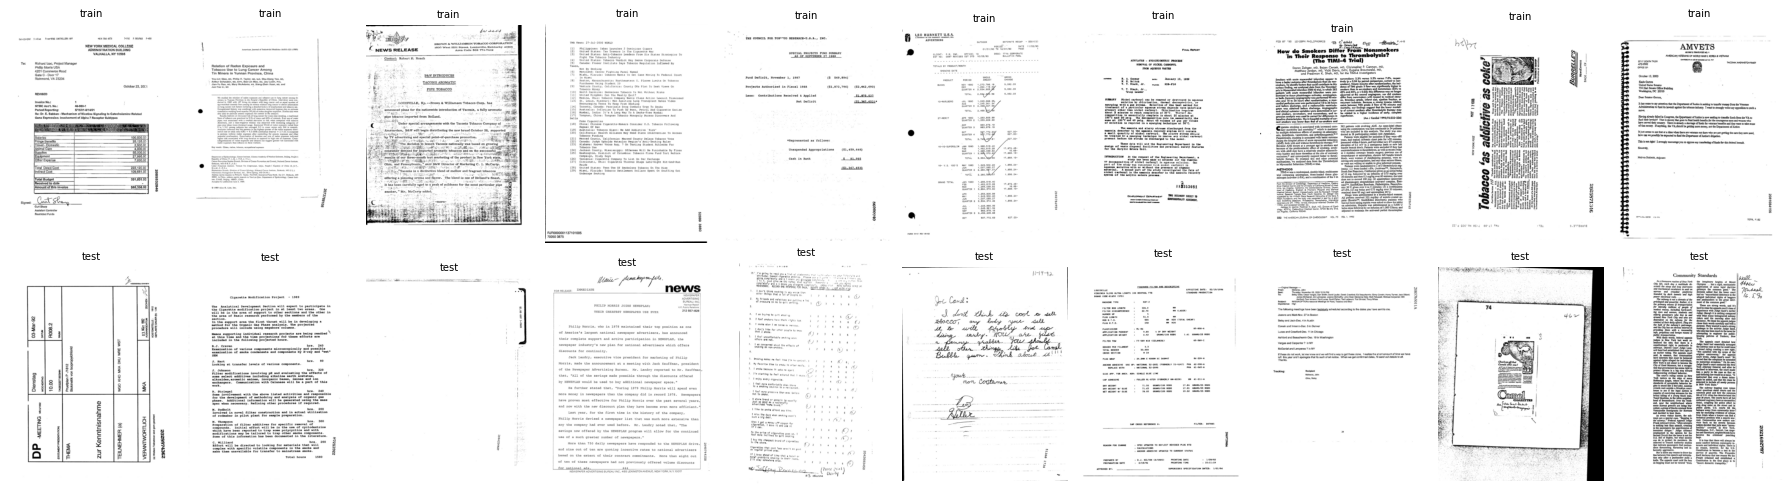

,train,test
mean,234.167,234.982
ink,0.080,0.077
w,766.648,765.693
file_kb,121.060,117.913


In [16]:
V.plot_train_vs_test(train_df, test_df, simpan=LAPORAN / "eda_train_vs_test.png")

Interpretasi EDA:

* Kelas praktis seimbang (sekitar 2.000 gambar per kelas), jadi akurasi adalah metrik yang adil dan tidak perlu bobot kelas.
* Hampir semua gambar setinggi 1.000 px, grayscale, satu halaman. Lebar bervariasi (halaman landscape untuk presentation).
* Rata-rata halaman per kelas memperlihatkan pola tata letak yang khas: kop surat di letter, blok To/From di memo dan email,
  teks padat berkolom di scientific_publication dan news_article, area gelap besar di file_folder dan advertisement.
* Distribusi statistik train dan test hampir sama, jadi tidak ada pergeseran distribusi yang mencolok.

## 4. Preprocessing & data augmentation

**Preprocessing**

* TIFF di-decode **sekali** lalu disimpan sebagai PNG grayscale setinggi `CACHE_H` px (sudah dilakukan saat scan).
  Decoding TIFF berulang tiap epoch sangat lambat.
* Mode 1-bit atau L selalu dikonversi ke `L` (0 sampai 255) sebelum dinormalisasi, lalu diulang ke 3 kanal agar cocok dengan bobot ImageNet.
* Dua *view*: `full` (seluruh halaman di-resize ke ukuran input model) dan `header` (33% bagian atas halaman, input berbentuk landscape).
* Normalisasi memakai mean dan std bawaan masing-masing backbone dari Hugging Face.

**Augmentasi** (hanya saat training), dipilih yang masuk akal untuk dokumen pindaian:

* rotasi kecil (plus minus 3 derajat), geser, skala, dan shear kecil, mensimulasikan skew pemindai;
* perubahan kecerahan dan kontras, mensimulasikan iluminasi tidak rata;
* blur Gaussian, derau, dan artefak kompresi JPEG, mensimulasikan faks dan kompresi;
* **tanpa flip horizontal maupun vertikal**, karena membalik teks dan tata letak.

Implementasinya di `src/dataset.py`. Di bagian ini juga dihitung **noise floor** (derau alat ukur), yaitu selisih akurasi terkecil yang masih bermakna.

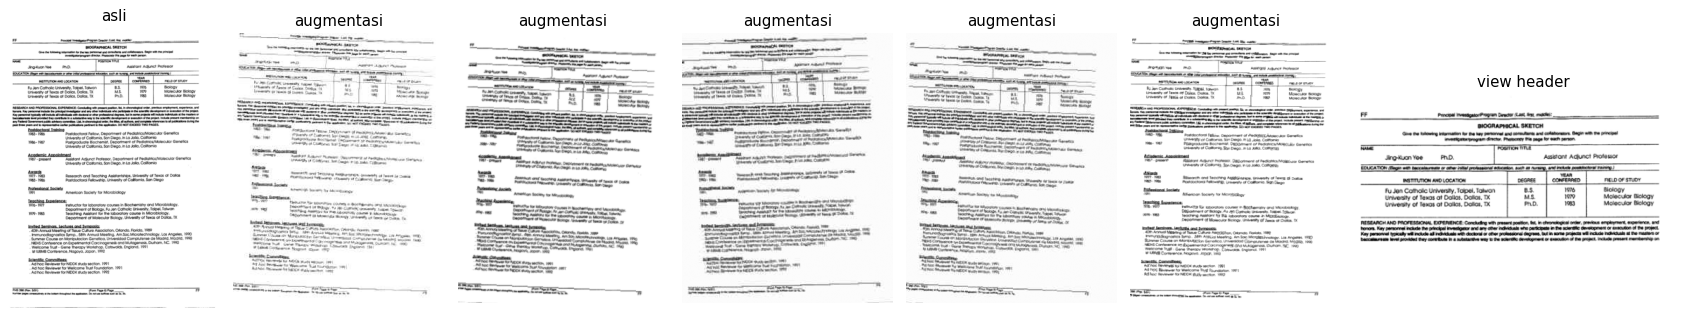

In [17]:
V.plot_augmentasi(train_df["cache"].iloc[0], simpan=LAPORAN / "augmentasi.png")

In [18]:
# ---- Noise floor: selisih akurasi terkecil yang masih bermakna ----
for p in (0.90, 0.93, 0.95):
    print(f"akurasi {p:.2f}: SE holdout (n={len(va_idx)}) = {100 * E.se_akurasi(p, len(va_idx)):.2f} poin | "
          f"SE test penuh (n=7994) = {100 * E.se_akurasi(p, 7994):.2f} poin")
GERBANG = 2 * E.se_akurasi(0.93, len(va_idx))
print(f"Ide yang kenaikannya < {100 * GERBANG:.2f} poin di holdout tidak dianggap nyata "
      "kecuali uji berpasangan (E.bandingkan) menyatakan sebaliknya.")

akurasi 0.90: SE holdout (n=6088) = 0.38 poin | SE test penuh (n=7994) = 0.34 poin
akurasi 0.93: SE holdout (n=6088) = 0.33 poin | SE test penuh (n=7994) = 0.29 poin
akurasi 0.95: SE holdout (n=6088) = 0.28 poin | SE test penuh (n=7994) = 0.24 poin
Ide yang kenaikannya < 0.65 poin di holdout tidak dianggap nyata kecuali uji berpasangan (E.bandingkan) menyatakan sebaliknya.


## 6. Konstruksi model

Arsitektur ada di `src/models.py`, loop training di `src/train.py`.

Semua backbone diunduh dari Hugging Face Hub. Kandidat dipilih supaya **beragam arsitektur** (konvolusi dan transformer)
dan **beragam view**, karena ensemble paling untung kalau kesalahan anggotanya tidak sama.

**Ringkasan riset literatur (dasar profil default `rvlcdip_ft`)**

| temuan | sumber | dampak ke notebook |
|---|---|---|
| Model citra murni mentok sekitar 92 sampai 94% di RVL-CDIP: DiT-base 92,1%, DiT-large 92,7%, DocXClassifier 94,2% | Li dkk. 2022 (DiT); tabel Larson dkk. 2023 | DiT saja hampir pasti di bawah target 95% |
| Model yang juga membaca **teks** naik ke 95 sampai 97%: Donut 95,3% (tanpa OCR), LayoutLMv3-base 95,4%, DocFormer 96,2% | Kim dkk. 2022 (Donut); Huang dkk. 2022; Larson dkk. 2023 | Donut ditambahkan sebagai anggota: membaca teks dari piksel, jadi tidak perlu OCR yang lambat |
| Ensemble model dengan sumber informasi berbeda (citra vs teks, halaman penuh vs potongan wilayah) menambah 1 sampai 2 poin | Das dkk. 2018 (region ensemble); Dauphinee dkk. 2019 (ensemble citra+teks) | DiT (tata letak visual) + Donut (teks) digabung lewat greedy ensemble selection di tahap 7 |
| Label RVL-CDIP berderau sekitar 8,1% (letter yang sebenarnya memo, invoice yang sebenarnya budget) dan sekitar sepertiga test punya kembaran/template di train | Larson dkk. 2023 | label smoothing 0,1; duplikat dengan label bertentangan dibuang; skor di atas sekitar 95% sebagian besar berasal dari kembaran dan template |
| Fine-tune DiT: AdamW, layer-wise LR decay, LR kecil karena checkpoint sudah di kelas yang sama | Li dkk. 2022; Bao dkk. 2022 (BEiT) | LR 1e-5 (large) dan 2e-5 (base), layer decay 0,9 dan 0,8, 2 epoch, epoch 0 (checkpoint apa adanya) ikut dibandingkan |

Perkiraan waktu profil `rvlcdip_ft` di Kaggle T4 x2: persiapan data sekitar 8 menit, DiT-large 2 epoch sekitar 25 menit,
Donut 2560x1920 untuk holdout dan test sekitar 30 sampai 40 menit (belum diukur di Kaggle; log menampilkan perkiraan sisa waktu
setelah 10 batch, dan `DOC_DONUT_H=1920` memangkasnya sekitar separuh), DiT-base 2 epoch sekitar 8 menit, ensemble dan visualisasi
beberapa menit. Total sekitar 1,3 sampai 1,5 jam.

**Profil `dokumen` (sekitar 1,5 jam di satu T4)**

| anggota | backbone (HF Hub) | pretrained | input |
|---|---|---|---|
| `dit_large_full224` (opsional, `DOC_DIT_LARGE=1`, tambah sekitar 1,5 jam) | `microsoft/dit-large` | self-supervised, 42 juta halaman dokumen IIT-CDIP | halaman penuh 224 |
| `dit_base_full224` | `microsoft/dit-base` | self-supervised, 42 juta halaman dokumen IIT-CDIP | halaman penuh 224 |
| `effv2s_full384` | `timm/tf_efficientnetv2_s.in21k_ft_in1k` | ImageNet-21k lalu 1k | halaman penuh 384 |

Di paper DiT, model ini mengungguli backbone ImageNet pada klasifikasi dokumen karena sudah mengenal tata letak dan tekstur teks.
Untuk DiT dipakai **layer-wise LR decay** (lapisan awal belajar lebih pelan) sesuai resep fine-tuning BEiT/DiT.

**Profil `lengkap` (sekitar 8 jam)**

| anggota | backbone (HF Hub) | pretrained | input |
|---|---|---|---|
| `cnxs_full384` | `timm/convnext_small.fb_in22k_ft_in1k_384` | ImageNet-22k lalu 1k | halaman penuh 384 |
| `effv2s_full448` | `timm/tf_efficientnetv2_s.in21k_ft_in1k` | ImageNet-21k lalu 1k | halaman penuh 448 |
| `effv2s_head` | `timm/tf_efficientnetv2_s.in21k_ft_in1k` | ImageNet-21k lalu 1k | header 256 x 576 |
| `swinv2b_full384` | `timm/swinv2_base_window12to24_192to384.ms_in22k_ft_in1k` | ImageNet-22k lalu 1k | halaman penuh 384 |
| `eva02b_full448` (opsional) | `timm/eva02_base_patch14_448.mim_in22k_ft_in22k_in1k` | MIM + ImageNet-22k | halaman penuh 448 |
| `dit_base_full224` (opsional, `IZIN_DIT`) | `microsoft/dit-base` | self-supervised IIT-CDIP tanpa label | halaman penuh 224 |

**Resep training** (mengikuti *ml-training-recipes*): AdamW, weight decay 0.05, warmup 1 epoch lalu cosine decay,
mixed precision (AMP), gradient clipping 1.0, **label smoothing 0.1** (membantu karena label RVL-CDIP berderau), drop path 0.1.
Checkpoint terbaik dipilih dari akurasi holdout per epoch.

Setiap anggota menyimpan `val_logits.npy`, `test_logits.npy` (dan versi TTA) di `artefak/<nama>/`, serta satu baris di
`artefak/ledger.csv` (experiment ledger).

Waktu terukur di satu GPU T4 (run pertama profil lengkap): ConvNeXt-S 384 sekitar 10,5 menit per epoch,
EfficientNetV2-S 448 sekitar 7,6 menit, EfficientNetV2-S header sekitar 5,6 menit. Dengan T4 x2 notebook memakai kedua GPU
(DataParallel), jadi waktunya kira-kira separuhnya. Kalau kuota tidak cukup, pecah ke beberapa sesi (lihat bagian Cara pakai).

In [19]:
t0 = time.time()
GAGAL = TR.latih_semua(ANGGOTA, ctx)
print("anggota gagal/dilewati:", GAGAL or "tidak ada", f"| waktu training {(time.time() - t0) / 60:.1f} menit")
pd.read_csv(cfg.artefak / "ledger.csv").iloc[:, :11]

config.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.21GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/416 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.21GB            

model.safetensors: downloading bytes:           |  0.00B            

... (26 outputs left out)

  [dit_base_rvlft] ep1 96/387 | 0.7 mnt | RAM 4.2/34 GB | GPU 1.1 GB, 0.0 GB
  [dit_base_rvlft] ep1 192/387 | 1.3 mnt | RAM 4.2/34 GB | GPU 1.1 GB, 0.0 GB
  [dit_base_rvlft] ep1 288/387 | 2.0 mnt | RAM 4.3/34 GB | GPU 1.1 GB, 0.0 GB
  [dit_base_rvlft] ep1 384/387 | 2.6 mnt | RAM 4.2/34 GB | GPU 1.1 GB, 0.0 GB
[dit_base_rvlft] epoch 1: loss 0.8151 | val acc 0.9302 | 2.8 mnt


dit_base_rvlft ep2:   0%|          | 0/387 [00:00<?, ?it/s]

  [dit_base_rvlft] ep2 96/387 | 0.7 mnt | RAM 4.3/34 GB | GPU 1.1 GB, 0.0 GB
  [dit_base_rvlft] ep2 192/387 | 1.3 mnt | RAM 4.3/34 GB | GPU 1.1 GB, 0.0 GB
  [dit_base_rvlft] ep2 288/387 | 1.9 mnt | RAM 4.3/34 GB | GPU 1.1 GB, 0.0 GB
  [dit_base_rvlft] ep2 384/387 | 2.6 mnt | RAM 4.3/34 GB | GPU 1.1 GB, 0.0 GB
[dit_base_rvlft] epoch 2: loss 0.7653 | val acc 0.9304 | 2.8 mnt
submission.csv sementara ditulis dari 3 anggota
waktu berjalan: 126 menit | RAM 3.8/34 GB | GPU 0.0 GB, 0.0 GB
submission.csv sementara ditulis dari 3 anggota
anggota gagal/dilewati: tidak ada | waktu training 104.1 menit


,waktu,nama,backbone,view,size,epochs,lr,augmentasi,val_acc,n_val,smoke
0,2026-11-04 10:17,dit_large_rvlft,microsoft/dit-large-finetuned-rvlcdip,full,224x224,2,0.00001,"affine+jitter+blur+jpeg+noise, tanpa flip",0.9427,6088,False
1,2026-11-04 11:22,donut_rvlcdip,naver-clova-ix/donut-base-finetuned-rvlcdip,full,2560x1920,0,0.00000,tanpa training,0.9512,6088,False
2,2026-11-04 11:29,dit_base_rvlft,microsoft/dit-base-finetuned-rvlcdip,full,224x224,2,0.00002,"affine+jitter+blur+jpeg+noise, tanpa flip",0.9307,6088,False


## 7. Model selection

Langkah pemilihan:

1. Bandingkan akurasi holdout tiap anggota, lengkap dengan interval kepercayaan.
2. Coba **semua kombinasi** anggota (rata-rata probabilitas) dan **greedy ensemble selection** (Caruana, boleh memilih ulang
   anggota yang sama sehingga bobot terbentuk otomatis).
3. Karena kombinasi dipilih memakai holdout yang sama, skornya sedikit optimis. Untuk estimasi jujur dipakai **split-half**:
   kombinasi dipilih di separuh holdout A lalu dinilai di separuh B, dan sebaliknya.
4. Kombinasi terbaik dibandingkan dengan anggota tunggal terbaik memakai uji berpasangan dari bagian noise floor.

In [20]:
pool = E.muat_pool(cfg.artefak, len(va_idx), len(test_df), pakai_tta=False)
tabel = E.tabel_anggota(pool, y_va)
display(tabel.round(4))

,anggota,val_acc,ci95_bawah,ci95_atas
0,donut_rvlcdip,0.9512,0.9458,0.9566
1,dit_large_rvlft,0.9427,0.9368,0.9485
2,dit_base_rvlft,0.9307,0.9243,0.9371


In [21]:
komb = E.semua_kombinasi(pool, y_va)
print("10 kombinasi terbaik (rata-rata peluang, dinilai di seluruh holdout):")
display(komb.head(10).round(4))
bobot_greedy, acc_greedy = E.greedy_selection(pool, y_va)
print("greedy selection:", dict(bobot_greedy), "| acc", round(acc_greedy, 4))
print("split-half (pilih di separuh, nilai di separuh lain):")
display(E.split_half(pool, y_va, cfg.seed).round(4))

10 kombinasi terbaik (rata-rata peluang, dinilai di seluruh holdout):


,kombinasi,n,acc
0,dit_large_rvlft + donut_rvlcdip,2,0.9537
1,dit_base_rvlft + donut_rvlcdip,2,0.9530
2,dit_base_rvlft + dit_large_rvlft + donut_rvlcdip,3,0.9517
3,donut_rvlcdip,1,0.9512
4,dit_large_rvlft,1,0.9427
5,dit_base_rvlft + dit_large_rvlft,2,0.9419
6,dit_base_rvlft,1,0.9307


greedy selection: {'donut_rvlcdip': 1, 'dit_large_rvlft': 1} | acc 0.9537
split-half (pilih di separuh, nilai di separuh lain):


,kombinasi,acc_kombinasi,tunggal,acc_tunggal
0,dit_large_rvlft + donut_rvlcdip,0.9514,donut_rvlcdip,0.9494
1,dit_large_rvlft + donut_rvlcdip,0.9560,donut_rvlcdip,0.9530


In [22]:
KOMBINASI = komb.iloc[0]["kombinasi"].split(" + ")
tunggal_terbaik = tabel.iloc[0]["anggota"]
p_ens = E.peluang(pool, {n: 1 for n in KOMBINASI})
uji = E.bandingkan(pool[tunggal_terbaik]["val"].argmax(1), p_ens.argmax(1), y_va, seed=cfg.seed)
print("kombinasi terpilih:", KOMBINASI)
print(f"vs {tunggal_terbaik}: selisih {100 * uji['selisih']:+.2f} poin, CI95 [{100 * uji['lo']:+.2f}, {100 * uji['hi']:+.2f}],",
      "nyata" if uji["nyata"] else "masih di dalam derau")

kombinasi terpilih: ['dit_large_rvlft', 'donut_rvlcdip']
vs donut_rvlcdip: selisih +0.25 poin, CI95 [+0.08, +0.43], nyata


## 8. Evaluasi model

Evaluasi dilakukan di holdout (fold berbasis grup kembar, jadi tidak ada gambar kembar yang bocor dari train).
Fokus pada pasangan kelas yang secara alami tertukar.

In [23]:
pred_ens = p_ens.argmax(1)
acc = accuracy_score(y_va, pred_ens); se = E.se_akurasi(acc, len(y_va))
print(f"Akurasi ensemble di holdout: {acc:.4f} (CI95 {acc - 1.96 * se:.4f} sampai {acc + 1.96 * se:.4f}, n={len(y_va)})")
print(classification_report(y_va, pred_ens, labels=list(range(NUM_CLASSES)), target_names=ctx.nama_kelas,
                            digits=3, zero_division=0))

Akurasi ensemble di holdout: 0.9537 (CI95 0.9484 sampai 0.9590, n=6088)
                        precision    recall  f1-score   support

         advertisement      0.949     0.967     0.958       367
                budget      0.960     0.958     0.959       380
                 email      0.978     0.994     0.986       308
           file_folder      0.951     0.988     0.969       415
                  form      0.896     0.889     0.892       386
           handwritten      0.980     0.961     0.970       410
               invoice      0.965     0.960     0.962       374
                letter      0.926     0.943     0.934       400
                  memo      0.965     0.944     0.955       378
          news_article      0.968     0.955     0.961       376
          presentation      0.915     0.924     0.919       394
         questionnaire      0.956     0.926     0.941       379
                resume      0.993     0.990     0.991       404
scientific_publication      0.9

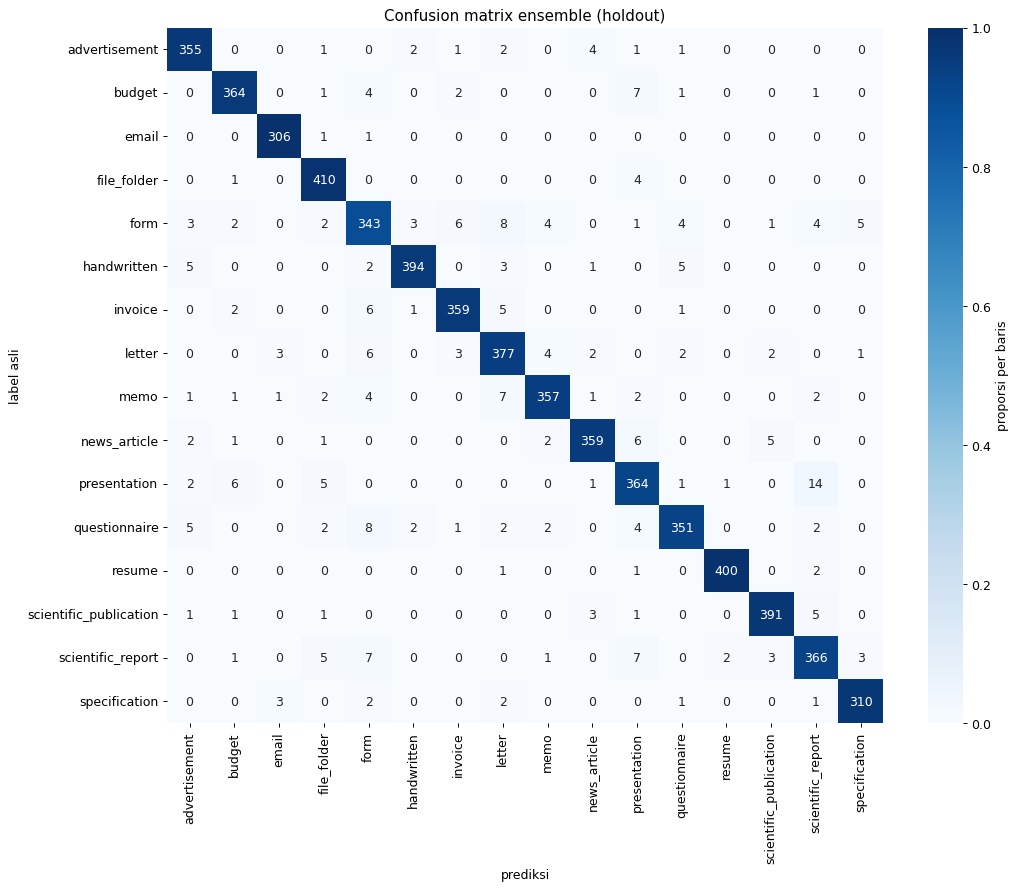

Pasangan paling sering tertukar (asli -> prediksi):


,asli,prediksi,jumlah
0,presentation,scientific_report,14
1,form,letter,8
2,questionnaire,form,8
3,budget,presentation,7
4,memo,letter,7
5,scientific_report,form,7
6,scientific_report,presentation,7
7,form,invoice,6
8,invoice,form,6
9,letter,form,6


In [24]:
cm = V.plot_confusion(y_va, pred_ens, CLASSES, simpan=LAPORAN / "confusion_matrix.png")
print("Pasangan paling sering tertukar (asli -> prediksi):")
display(V.pasangan_tertukar(cm, CLASSES))

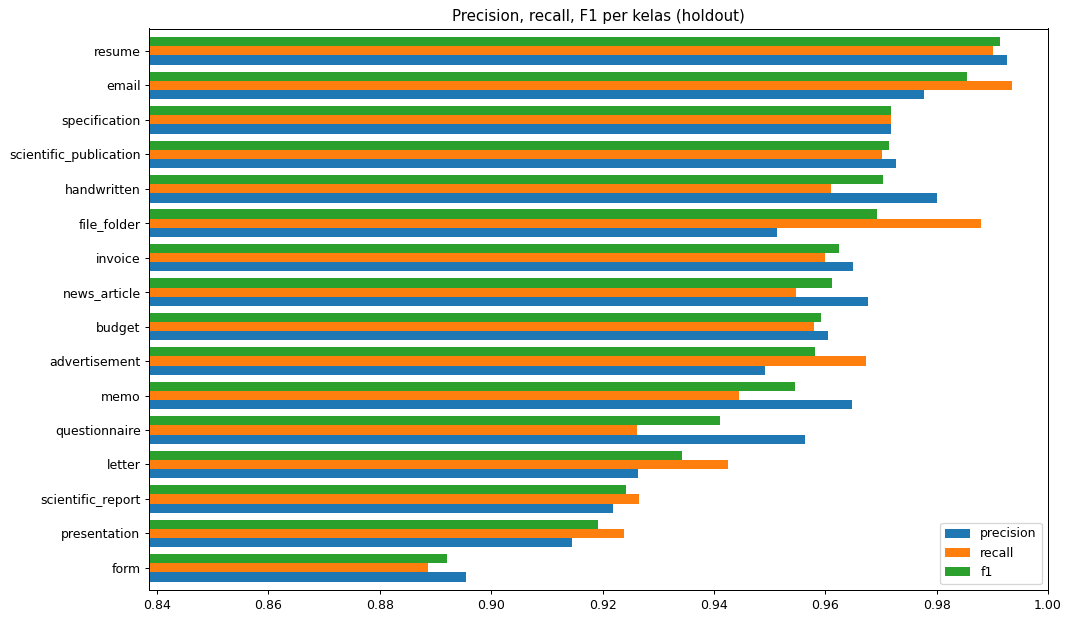

,precision,recall,f1,support
form,0.896,0.889,0.892,386
presentation,0.915,0.924,0.919,394
scientific_report,0.922,0.927,0.924,395
letter,0.926,0.942,0.934,400
questionnaire,0.956,0.926,0.941,379
memo,0.965,0.944,0.955,378
advertisement,0.949,0.967,0.958,367
budget,0.960,0.958,0.959,380
news_article,0.968,0.955,0.961,376
invoice,0.965,0.960,0.962,374


akurasi top-k: {'top-1': 0.9537, 'top-2': 0.9829, 'top-3': 0.9901}


In [25]:
metrik_kelas = V.plot_metrik_per_kelas(y_va, pred_ens, CLASSES, simpan=LAPORAN / "metrik_per_kelas.png")
display(metrik_kelas.round(3))
topk = V.tabel_topk(p_ens, y_va)
print("akurasi top-k:", topk.round(4).to_dict())

**Precision vs recall per kelas.** Kelas dengan recall rendah sering "dicuri" kelas lain (gambar kelas itu ditebak sebagai kelas lain),
sedangkan precision rendah berarti kelas itu menjadi tempat buangan tebakan. Akurasi top-2 yang jauh di atas top-1 menandakan
sebagian besar kesalahan hanyalah pilihan kedua yang sangat dekat, biasanya pasangan ambigu seperti letter dan memo.

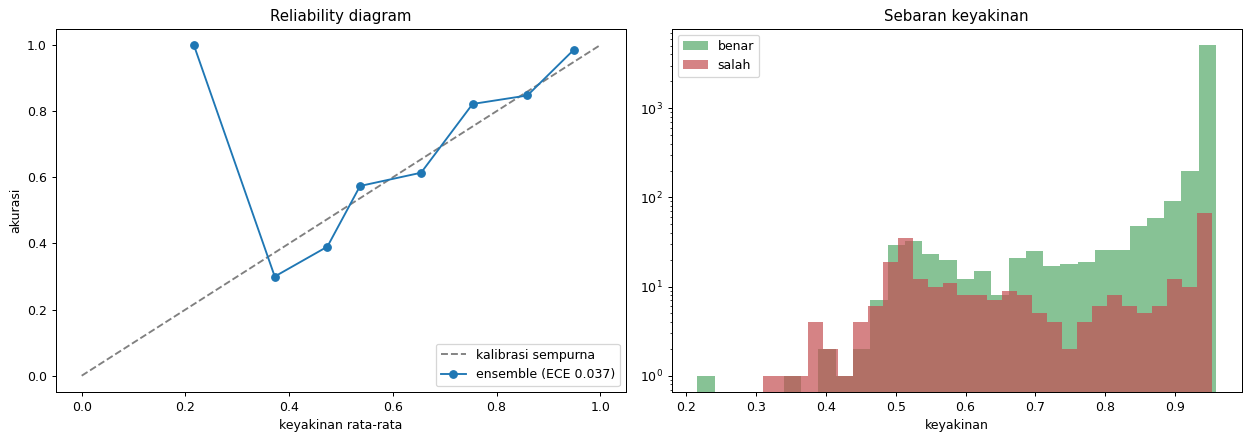

Expected Calibration Error: 0.0368


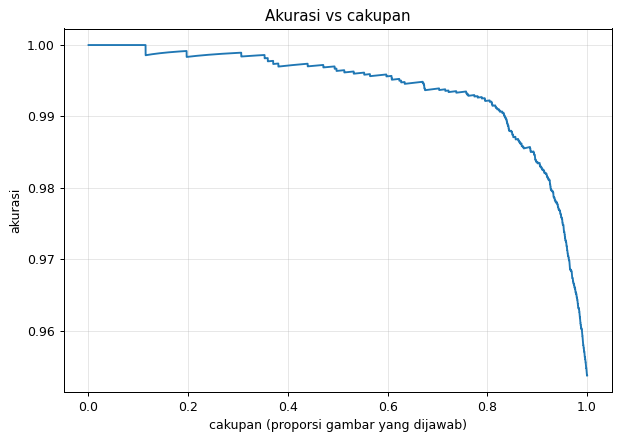

,cakupan,akurasi
0,0.50,0.9964
1,0.80,0.9922
2,0.90,0.9836
3,0.95,0.9756
4,1.00,0.9537


In [26]:
ECE = V.plot_kalibrasi(p_ens, y_va, simpan=LAPORAN / "kalibrasi.png")
print(f"Expected Calibration Error: {ECE:.4f}")
display(V.plot_cakupan(p_ens, y_va, simpan=LAPORAN / "akurasi_vs_cakupan.png").round(4))

**Kalibrasi.** Reliability diagram membandingkan keyakinan model dengan akurasi nyata; garis di bawah diagonal berarti model terlalu
yakin. Histogram memperlihatkan bahwa prediksi salah umumnya punya keyakinan lebih rendah. **Akurasi vs cakupan** menunjukkan
berapa akurasi kalau hanya halaman yang paling yakin yang dijawab otomatis, misalnya untuk alur kerja nyata di mana halaman
yang ragu dikirim ke manusia.

## 9. Visualisasi data & hasil

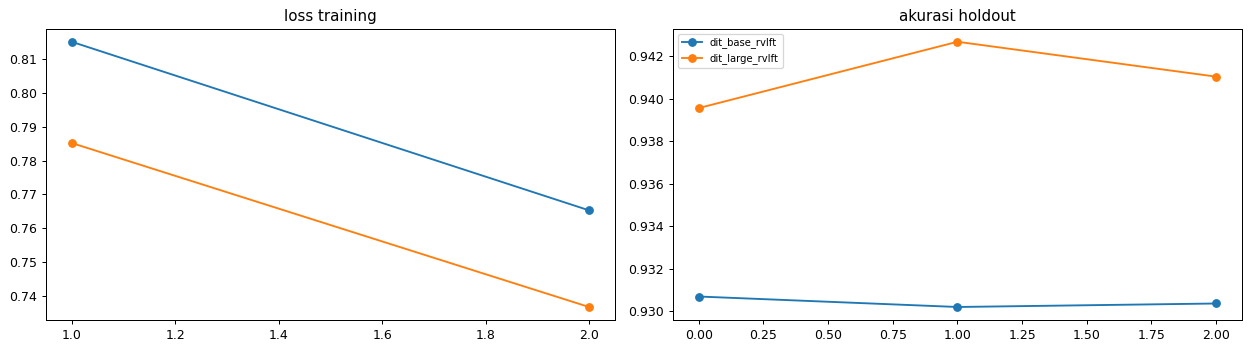

In [27]:
V.plot_kurva_training(cfg.artefak, simpan=LAPORAN / "kurva_training.png")

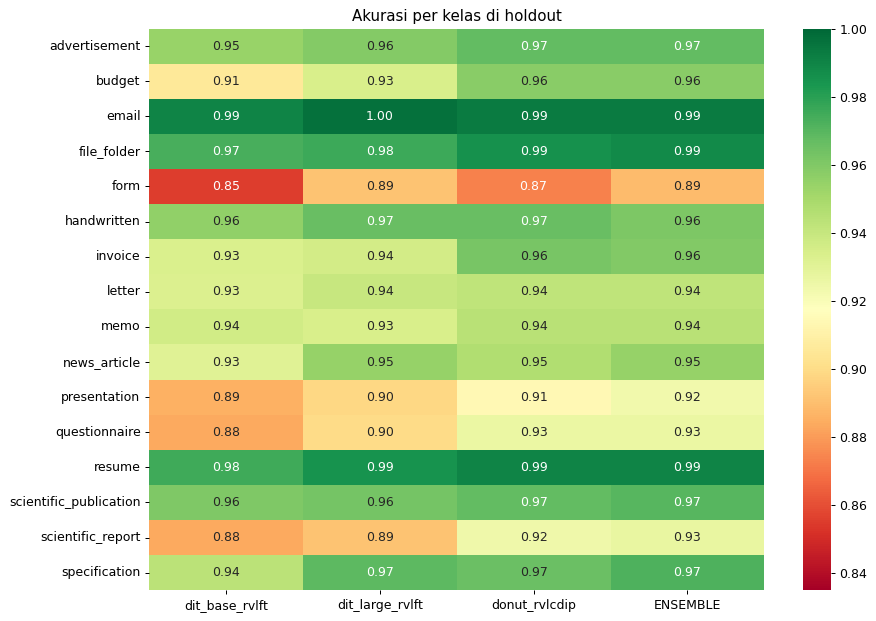

In [28]:
akurasi_kelas = V.plot_akurasi_per_kelas(pool, pred_ens, y_va, CLASSES, simpan=LAPORAN / "akurasi_per_kelas.png")

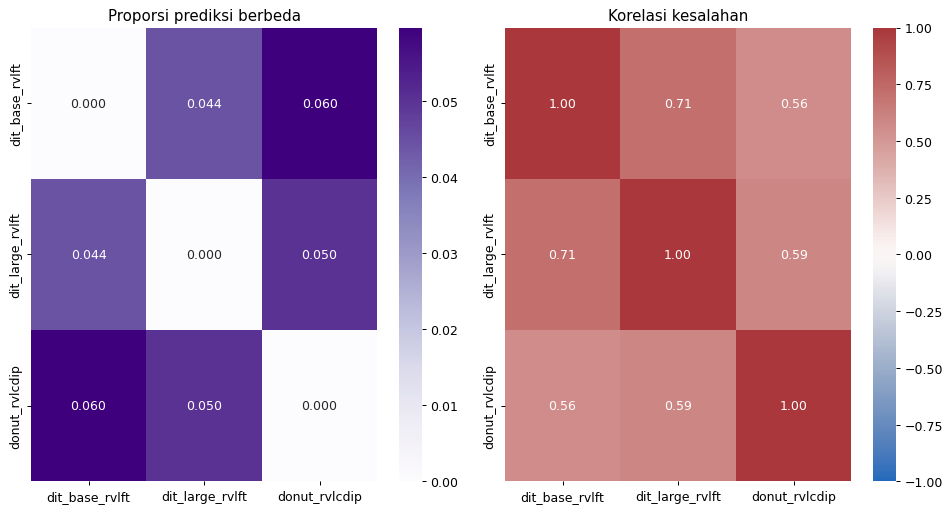

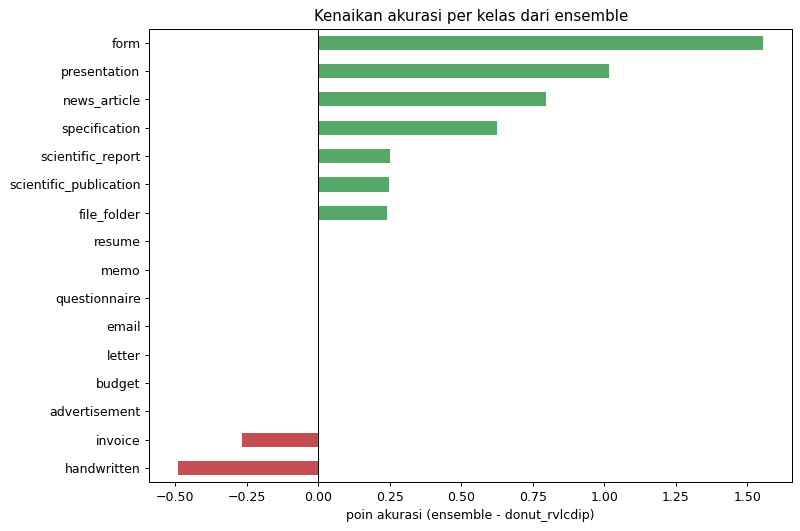

In [29]:
keragaman = V.plot_keragaman_anggota(pool, y_va, simpan=LAPORAN / "keragaman_anggota.png")
gain = V.plot_gain_ensemble(pool, pred_ens, y_va, CLASSES, simpan=LAPORAN / "gain_ensemble.png")

**Keragaman anggota.** Ensemble hanya menolong kalau anggotanya berbeda pendapat dan kesalahannya tidak berkorelasi.
Pasangan dengan proporsi prediksi berbeda tinggi dan korelasi kesalahan rendah (biasanya DiT vs Donut, karena yang satu melihat
tata letak dan yang lain membaca teks) adalah sumber kenaikan akurasi ensemble. Grafik kenaikan per kelas memperlihatkan
kelas mana yang paling diuntungkan oleh penggabungan.

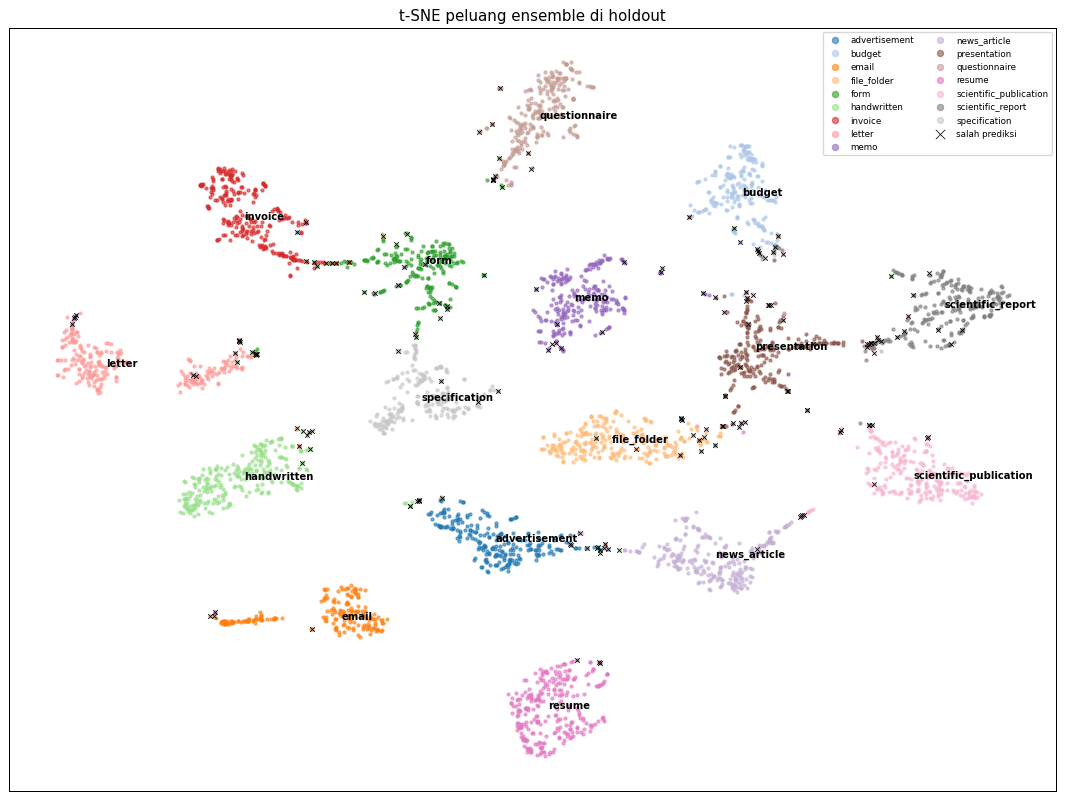

In [30]:
emb = V.plot_tsne(p_ens, y_va, CLASSES, seed=cfg.seed, simpan=LAPORAN / "tsne_holdout.png")

**t-SNE** memproyeksikan vektor peluang 16 dimensi setiap gambar holdout ke 2 dimensi. Kelas yang membentuk gugus rapat dan terpisah
adalah kelas yang mudah; gugus yang bersentuhan menunjukkan pasangan kelas yang tertukar, dan tanda x (salah prediksi)
terkumpul di perbatasan gugus tersebut atau di dalam gugus kelas lain (kandidat label salah).

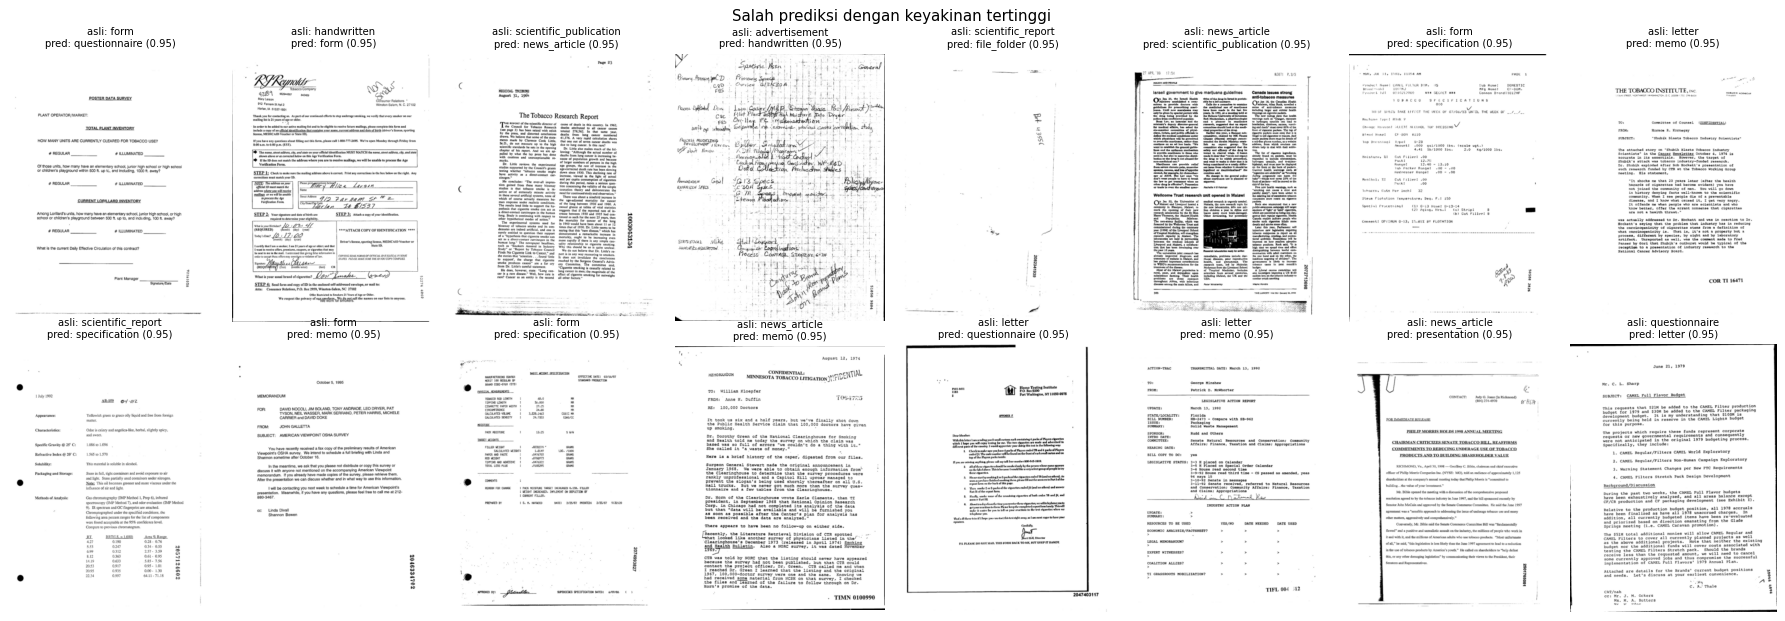

In [31]:
conf = (p_ens / len(KOMBINASI)).max(1)
V.plot_salah_prediksi(train_df["cache"].values[va_idx], y_va, pred_ens, conf, CLASSES,
                      simpan=LAPORAN / "salah_prediksi.png")

In [32]:
# Grad-CAM untuk anggota CNN (kalau ada di profil ini): memastikan model melihat isi dokumen, bukan tepi pindaian
cnn = [a for a in ANGGOTA if a["backend"] == "timm" and not any(k in a["hub"] for k in ("swin", "eva", "vit"))]
if cnn:
    a = cnn[0]
    model, mean, std = buat_model(a, CLASSES, cfg.pretrained)
    model.load_state_dict(torch.load(cfg.checkpoint_dir / a["name"] / "best.pt", map_location="cpu")); model.eval()
    contoh = [va_idx[np.where(y_va == c)[0][0]] for c in range(NUM_CLASSES) if (y_va == c).any()][:8]
    V.plot_gradcam(model, a, mean, std, train_df["cache"].values[contoh], train_df["label"].values[contoh], CLASSES,
                   simpan=LAPORAN / "gradcam.png")
    del model
else:
    print("profil ini tidak memiliki anggota CNN, Grad-CAM dilewati")

profil ini tidak memiliki anggota CNN, Grad-CAM dilewati


Loading weights:   0%|          | 0/212 [00:00<?, ?it/s]

pemetaan label RVL-CDIP -> lomba: {'advertisement': 4, 'budget': 10, 'email': 2, 'file_folder': 8, 'form': 1, 'handwritten': 3, 'invoice': 11, 'letter': 0, 'memo': 15, 'news_article': 9, 'presentation': 12, 'questionnaire': 13, 'resume': 14, 'scientific_publication': 6, 'scientific_report': 5, 'specification': 7}


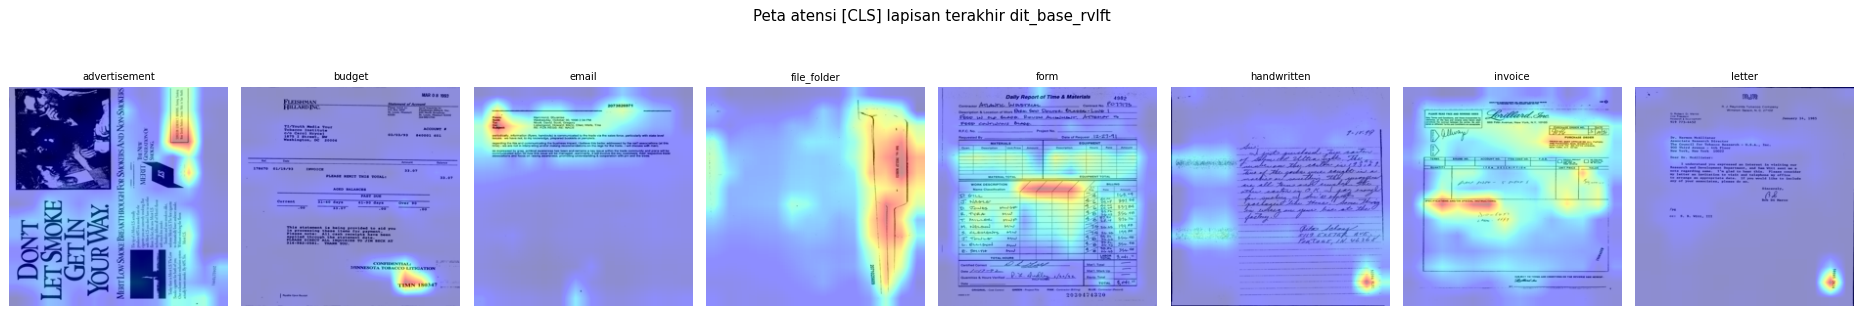

In [33]:
# Peta atensi DiT: bagian halaman yang diperhatikan token [CLS] di lapisan terakhir
dit = [a for a in ANGGOTA if a["backend"] == "hf"]
dit = sorted(dit, key=lambda a: "base" not in a["hub"])          # pilih DiT-base dulu (lebih ringan)
if dit:
    a = dit[0]
    ckpt = [p for p in (cfg.checkpoint_dir / a["name"] / "best.pt", cfg.artefak / a["name"] / "best.pt") if p.exists()]
    try:
        model, _, _ = buat_model(a, CLASSES, cfg.pretrained)
        if ckpt:
            model.load_state_dict(torch.load(ckpt[0], map_location="cpu"))
        model = model.to(cfg.device).eval()
        contoh = [va_idx[np.where(y_va == c)[0][0]] for c in range(NUM_CLASSES) if (y_va == c).any()][:8]
        V.plot_atensi_dit(model, a, train_df["cache"].values[contoh], train_df["label"].values[contoh], CLASSES,
                          simpan=LAPORAN / "atensi_dit.png")
        del model
    except Exception as e:
        print("peta atensi dilewati:", type(e).__name__, e)

**Peta atensi DiT** (dan Grad-CAM untuk CNN) dipakai untuk memastikan model melihat isi dokumen: kop surat, blok header,
tabel, judul, dan tanda tangan, bukan artefak pindaian di tepi halaman atau nomor arsip. Kalau atensi menumpuk di tepi,
itu tanda model memakai jalan pintas yang tidak akan berlaku di data baru.

## 10. Optimalisasi performa model

Tiga optimalisasi diuji, masing-masing dengan sakelar dan dibandingkan nyala vs mati di holdout yang sama:

1. **TTA** (test-time augmentation) tanpa flip: rata-rata probabilitas dari tampilan asli dan dua tampilan yang sedikit diperbesar
   lalu dipotong tengah.
2. **Bobot ensemble** hasil greedy selection, dibandingkan dengan rata-rata biasa.
3. **Anggota teks (OCR)** opsional (`DOC_OCR=1`): Tesseract membaca teks halaman (`src/ocr.py`), lalu TF-IDF kata dan karakter + Logistic Regression.
   Teks membantu kelas seperti memo, email, letter, dan invoice. OCR dijalankan pada TIFF asli (1000 px).
   Untuk 40 ribu halaman dengan 4 core CPU perkiraannya 3 sampai 5 jam, jadi defaultnya mati dan hasilnya di-cache ke `artefak/`.

Setiap perubahan hanya diadopsi kalau lolos uji berpasangan (`bandingkan`), sesuai prinsip noise floor.

In [34]:
# 10.1 TTA
pool_tta = E.muat_pool(cfg.artefak, len(va_idx), len(test_df), pakai_tta=True)
p_tta = E.peluang(pool_tta, {n: 1 for n in KOMBINASI})
u = E.bandingkan(pred_ens, p_tta.argmax(1), y_va, seed=cfg.seed)
print(f"TTA: {accuracy_score(y_va, pred_ens):.4f} -> {accuracy_score(y_va, p_tta.argmax(1)):.4f} | "
      f"CI95 [{100 * u['lo']:+.2f}, {100 * u['hi']:+.2f}] poin")
PAKAI_TTA_FINAL = cfg.pakai_tta and u["selisih"] >= 0
POOL_FINAL = pool_tta if PAKAI_TTA_FINAL else pool
print("TTA dipakai untuk submission:", PAKAI_TTA_FINAL)

TTA: 0.9537 -> 0.9532 | CI95 [-0.11, +0.00] poin
TTA dipakai untuk submission: False


In [35]:
# 10.2 Anggota teks dari OCR (opsional, DOC_OCR=1)
if cfg.pakai_ocr:
    from src.ocr import latih_anggota_ocr
    print("akurasi anggota OCR di holdout:", round(latih_anggota_ocr(ctx), 4))
    POOL_FINAL = E.muat_pool(cfg.artefak, len(va_idx), len(test_df), pakai_tta=PAKAI_TTA_FINAL)
else:
    print("anggota OCR dilewati (DOC_OCR=0)")

anggota OCR dilewati (DOC_OCR=0)


In [36]:
# 10.3 Bobot akhir: rata-rata kombinasi terbaik, diganti bobot greedy hanya kalau kenaikannya nyata
BOBOT_FINAL, info = E.pilih_bobot_final(POOL_FINAL, y_va, cfg.seed)
print("kombinasi rata-rata terbaik:", info["kombinasi_rata"], "| acc", round(info["acc_rata"], 4))
print("bobot greedy:", info["bobot_greedy"], "| acc", round(info["acc_greedy"], 4),
      f"| CI95 selisih [{100 * info['uji']['lo']:+.2f}, {100 * info['uji']['hi']:+.2f}]")
print("bobot final:", BOBOT_FINAL, f"| akurasi holdout konfigurasi akhir: {info['acc_final']:.4f}")

kombinasi rata-rata terbaik: ['dit_large_rvlft', 'donut_rvlcdip'] | acc 0.9537
bobot greedy: {'donut_rvlcdip': 1, 'dit_large_rvlft': 1} | acc 0.9537 | CI95 selisih [+0.00, +0.00]
bobot final: {'dit_large_rvlft': 1, 'donut_rvlcdip': 1} | akurasi holdout konfigurasi akhir: 0.9537


In [37]:
# Submission: urutan id mengikuti test.csv, label integer 0..15
p_test = E.peluang(POOL_FINAL, BOBOT_FINAL, "test")
sub = E.tulis_submisi(test_df["id"].values, p_test, cfg.submission_path, NUM_CLASSES)
if not cfg.smoke:
    assert len(sub) == len(sub_contoh) and (sub["id"].values == sub_contoh["id"].values).all()
print("tersimpan:", cfg.submission_path); display(sub.head())
print("distribusi prediksi:", sub["label"].map(CLASSES).value_counts().to_dict())

riwayat = cfg.artefak / "riwayat_submisi"; riwayat.mkdir(exist_ok=True)
for nama, beda in E.beda_submisi(sub, riwayat):     # sub-diff terhadap submission sebelumnya
    print(f"vs {nama}: {beda} label berbeda ({100 * beda / len(sub):.2f}%)")
sub.to_csv(riwayat / (time.strftime("%Y%m%d_%H%M") + ".csv"), index=False)

tersimpan: /kaggle/working/submission.csv


,id,label
0,test_00001,0
1,test_00002,0
2,test_00003,1
3,test_00004,4
4,test_00005,13


distribusi prediksi: {'file_folder': 523, 'budget': 514, 'handwritten': 509, 'scientific_publication': 509, 'email': 504, 'scientific_report': 501, 'advertisement': 499, 'resume': 499, 'letter': 499, 'invoice': 496, 'questionnaire': 495, 'presentation': 493, 'news_article': 492, 'memo': 489, 'form': 487, 'specification': 485}


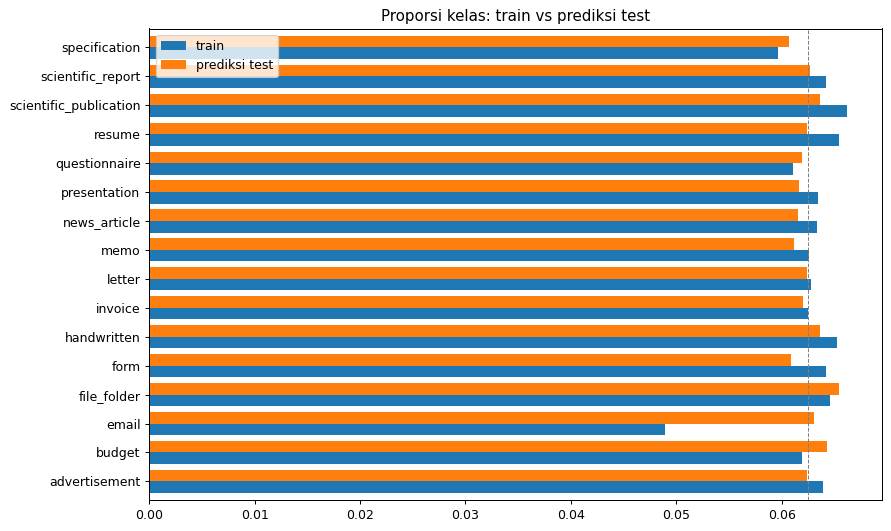

,train,prediksi test
advertisement,0.0639,0.0624
budget,0.0619,0.0643
email,0.0490,0.0630
file_folder,0.0646,0.0654
form,0.0642,0.0609
handwritten,0.0652,0.0637
invoice,0.0625,0.0620
letter,0.0628,0.0624
memo,0.0626,0.0612
news_article,0.0634,0.0615


In [38]:
V.plot_distribusi_prediksi(sub, train_df, CLASSES, simpan=LAPORAN / "distribusi_prediksi_test.png").round(4)

Proporsi kelas prediksi test seharusnya mendekati proporsi train (sekitar 1/16 per kelas). Kelas yang jauh lebih sering
diprediksi menandakan bias model ke kelas tersebut, biasanya kelas "tempat buangan" seperti form atau letter.

In [39]:
# Ringkasan untuk README: disimpan ke reports/ (folder ini di-commit)
import shutil
shutil.copy(cfg.artefak / "ledger.csv", LAPORAN / "ledger.csv")
ringkas = dict(profil=cfg.profil, anggota=[a["name"] for a in ANGGOTA], gagal=GAGAL,
               akurasi_anggota={r.anggota: round(r.val_acc, 4) for r in tabel.itertuples()},
               kombinasi=KOMBINASI, bobot_final={k: int(v) for k, v in BOBOT_FINAL.items()}, tta=bool(PAKAI_TTA_FINAL),
               acc_holdout_final=round(float(info["acc_final"]), 4), n_holdout=int(len(y_va)),
               data_cleaning=dict(n_pairs=int(n_pairs), konflik_dibuang=int(n_awal - len(train_df)), duplikat_test=dup_test),
               pasangan_tertukar=V.pasangan_tertukar(cm, CLASSES, 6).values.tolist(),
               akurasi_per_kelas_ensemble=akurasi_kelas["ENSEMBLE"].round(4).to_dict(),
               topk={k: round(v, 4) for k, v in topk.items()}, ece=round(ECE, 4),
               f1_per_kelas=metrik_kelas["f1"].round(4).to_dict(),
               menit=round(cfg.jam_berjalan() * 60, 1))
(LAPORAN / "ringkasan_hasil.json").write_text(json.dumps(ringkas, indent=2, ensure_ascii=False))
print(json.dumps(ringkas, indent=2, ensure_ascii=False))

{
  "profil": "rvlcdip_ft",
  "anggota": [
    "dit_large_rvlft",
    "donut_rvlcdip",
    "dit_base_rvlft"
  ],
  "gagal": [],
  "akurasi_anggota": {
    "donut_rvlcdip": 0.9512,
    "dit_large_rvlft": 0.9427,
    "dit_base_rvlft": 0.9307
  },
  "kombinasi": [
    "dit_large_rvlft",
    "donut_rvlcdip"
  ],
  "bobot_final": {
    "dit_large_rvlft": 1,
    "donut_rvlcdip": 1
  },
  "tta": false,
  "acc_holdout_final": 0.9537,
  "n_holdout": 6088,
  "data_cleaning": {
    "n_pairs": 9275,
    "konflik_dibuang": 1099,
    "duplikat_test": {
      "md5_identik": 25,
      "phash_identik": 119,
      "n_test": 7994
    }
  },
  "pasangan_tertukar": [
    [
      "presentation",
      "scientific_report",
      14
    ],
    [
      "form",
      "letter",
      8
    ],
    [
      "questionnaire",
      "form",
      8
    ],
    [
      "budget",
      "presentation",
      7
    ],
    [
      "memo",
      "letter",
      7
    ],
    [
      "scientific_report",
      "form",
      7


## Ringkasan dan langkah lanjutan

* Hasil tiap anggota tercatat di `reports/ledger.csv` (backbone, resolusi, augmentasi, akurasi holdout, akurasi per kelas).
* Ringkasan angka akhir ada di `reports/ringkasan_hasil.json`, dan grafik di `reports/*.png`. Keduanya dikutip di README.
* Interpretasi lengkap ada di README bagian **Laporan interpretasi**.
* Ide lanjutan (uji satu per satu dengan sakelar): fine-tune Donut beberapa ratus langkah, DiT pada resolusi 384 dengan
  interpolasi posisi, dan anggota multimodal LayoutLMv3 kalau OCR cukup cepat.